# Pulse train after the Pockels cell

Fast Photodiode (Thorlabs SM05PD2A) after the cell, GW-Instek GDS-1104B, 2 ns per sample, 2 ms record.</br>
Two recordings: 40 MHz and 20 MHz picking (C3, C4)

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from scipy.signal import find_peaks

In [2]:
# ==========================================================
# Manuscript figure style
# ==========================================================

MM = 1 / 25.4               # inch per mm
WIDTH_1COL = 89             # mm, single column
WIDTH_2COL = 183            # mm, full page width

PAPER_FONT = "Arial"
PAPER_FONTSIZE = 10          # pt, all text in the figure
PAPER_PANELSIZE = 12         # pt, the panel letters a, b, ...
PAPER_LINEWIDTH = 1.0       # pt, axes, ticks, bar and box edges, reference lines
PAPER_MARKERSIZE = 3        # pt, one dot per position
PAPER_FORMATS = ("pdf", "svg", "png")   # pdf for submission, svg to edit, png to look at
PAPER_PNG_DPI = 300

PAPER_RC = {
    "font.family": "sans-serif",
    "font.sans-serif": [PAPER_FONT, "Helvetica", "DejaVu Sans"],
    "mathtext.default": "regular",          # superscripts in $...$ use the same font
    "font.size": PAPER_FONTSIZE,
    "axes.titlesize": PAPER_FONTSIZE,
    "axes.labelsize": PAPER_FONTSIZE,
    "xtick.labelsize": PAPER_FONTSIZE,
    "ytick.labelsize": PAPER_FONTSIZE,
    "legend.fontsize": PAPER_FONTSIZE,
    "axes.linewidth": PAPER_LINEWIDTH,
    "xtick.major.width": PAPER_LINEWIDTH,
    "ytick.major.width": PAPER_LINEWIDTH,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "lines.linewidth": PAPER_LINEWIDTH,
    "patch.linewidth": PAPER_LINEWIDTH,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",                 # text stays text in Illustrator / Inkscape
    "pdf.fonttype": 42,                     # embedded TrueType, editable in Illustrator
    "figure.dpi": PAPER_PNG_DPI,
}


def paper_style():
    """Use as `with paper_style():` around everything that builds and saves a manuscript figure."""
    return plt.rc_context(PAPER_RC)


def panel_label(ax, letter, dx=-28, dy=4):
    """Bold lower-case letter at the top left of a panel. dx, dy in points from the axes corner."""
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(dx, dy),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=PAPER_PANELSIZE, fontweight="bold")


def save_paper(fig, name):
    """Save at exactly the size the figure was made with (no tight bbox, so widths stay in mm)."""
    for ext in PAPER_FORMATS:
        fig.savefig(FIG / f"{name}.{ext}", dpi=PAPER_PNG_DPI if ext == "png" else None)
    print("saved", ", ".join(f"{name}.{ext}" for ext in PAPER_FORMATS))

In [3]:
# load files
OSC = Path("data/oscilloscope")
CACHE = Path("data/derived/oscilloscope")
FIG = Path("figures")
CACHE.mkdir(parents=True, exist_ok=True)
FIG.mkdir(exist_ok=True)

RUNS = ["2026-10-12_40mhz", "2026-10-12_20mhz"]
RUN_LABEL = ["40 MHz", "20 MHz"]
F_PICK = np.array([40.0, 20.0])          # MHz, as set on the BME
F_LASER = 79.8                           # MHz, unpicked

cmap = matplotlib.colormaps.get_cmap('viridis')

RUN_COLORS = [
            "#3e68ad",   # case3  40 MHz
            "#19154b"]   # case4  20 MHz

C_REF = "tab:red"
C_GUIDE = "0.75"

## Reading GDS-1104B csv data

24 `key,value` lines, then `Waveform Data,`, then time/volts pairs. arrays are cached as .npy.

In [4]:
def read_scope(name):
    """Header dict, time (s) and voltage (V) for one GDS-1104B export."""
    path = OSC / f"{name}.CSV"
    lines = path.read_text().splitlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("Waveform Data")) + 1

    head = {}
    for l in lines[:start - 1]:
        if "," in l:
            k, v = l.split(",", 1)
            head[k.strip()] = v.strip().rstrip(",")

    npy = CACHE / f"{name}.npy"
    if npy.exists():
        t, v = np.load(npy)
    else:
        t, v = np.loadtxt(path, delimiter=",", skiprows=start, usecols=(0, 1), unpack=True)
        np.save(npy, np.vstack([t, v]))
    return head, t, v


HEAD, TIME, VOLT = {}, {}, {}
for name in RUNS:
    HEAD[name], TIME[name], VOLT[name] = read_scope(name)
    h = HEAD[name]
    dt = float(h["Sampling Period"])
    print(f"{name}:  {len(TIME[name])} samples, {dt*1e9:.1f} ns/sample, "
          f"{len(TIME[name])*dt*1e3:.2f} ms record, {float(h['Vertical Scale'])*1e3:.0f} mV/div, "
          f"source {h['Source']}")

DT = float(HEAD[RUNS[0]]["Sampling Period"])

2026-10-12_40mhz:  1000000 samples, 2.0 ns/sample, 2.00 ms record, 50 mV/div, source CH1


2026-10-12_20mhz:  1000000 samples, 2.0 ns/sample, 2.00 ms record, 50 mV/div, source CH1


## Baseline

The photodiode rings a little after each pulse and undershoots below zero. The undershoot is not
light, so the trace is baselined on the off samples and clipped at zero.

In [5]:
SIGNAL = {}
for name in RUNS:
    v = VOLT[name]
    base = np.median(v[v <= 0])
    SIGNAL[name] = np.clip(v - base, 0, None)
    print(f"{name}:  baseline {base*1e3:+.2f} mV, peak {SIGNAL[name].max()*1e3:.1f} mV, "
          f"{100*(v == 0).mean():.0f}% of samples exactly zero")

2026-10-12_40mhz:  baseline +0.00 mV, peak 82.0 mV, 69% of samples exactly zero
2026-10-12_20mhz:  baseline +0.00 mV, peak 82.0 mV, 80% of samples exactly zero


## Fig. 4: Oscilloscope trace and figure

Regarding pulse train histogram:</br>
Every pulse found, its height and the gap to the previous one. The interval histogram is the
interesting part here: an ideal picker shows one line at 1/f_pick and nothing else. Anything at 12.5 ns
is an 80 MHz pulse the cell failed to reject.

saved oscilloscope_traces.pdf, oscilloscope_traces.svg, oscilloscope_traces.png


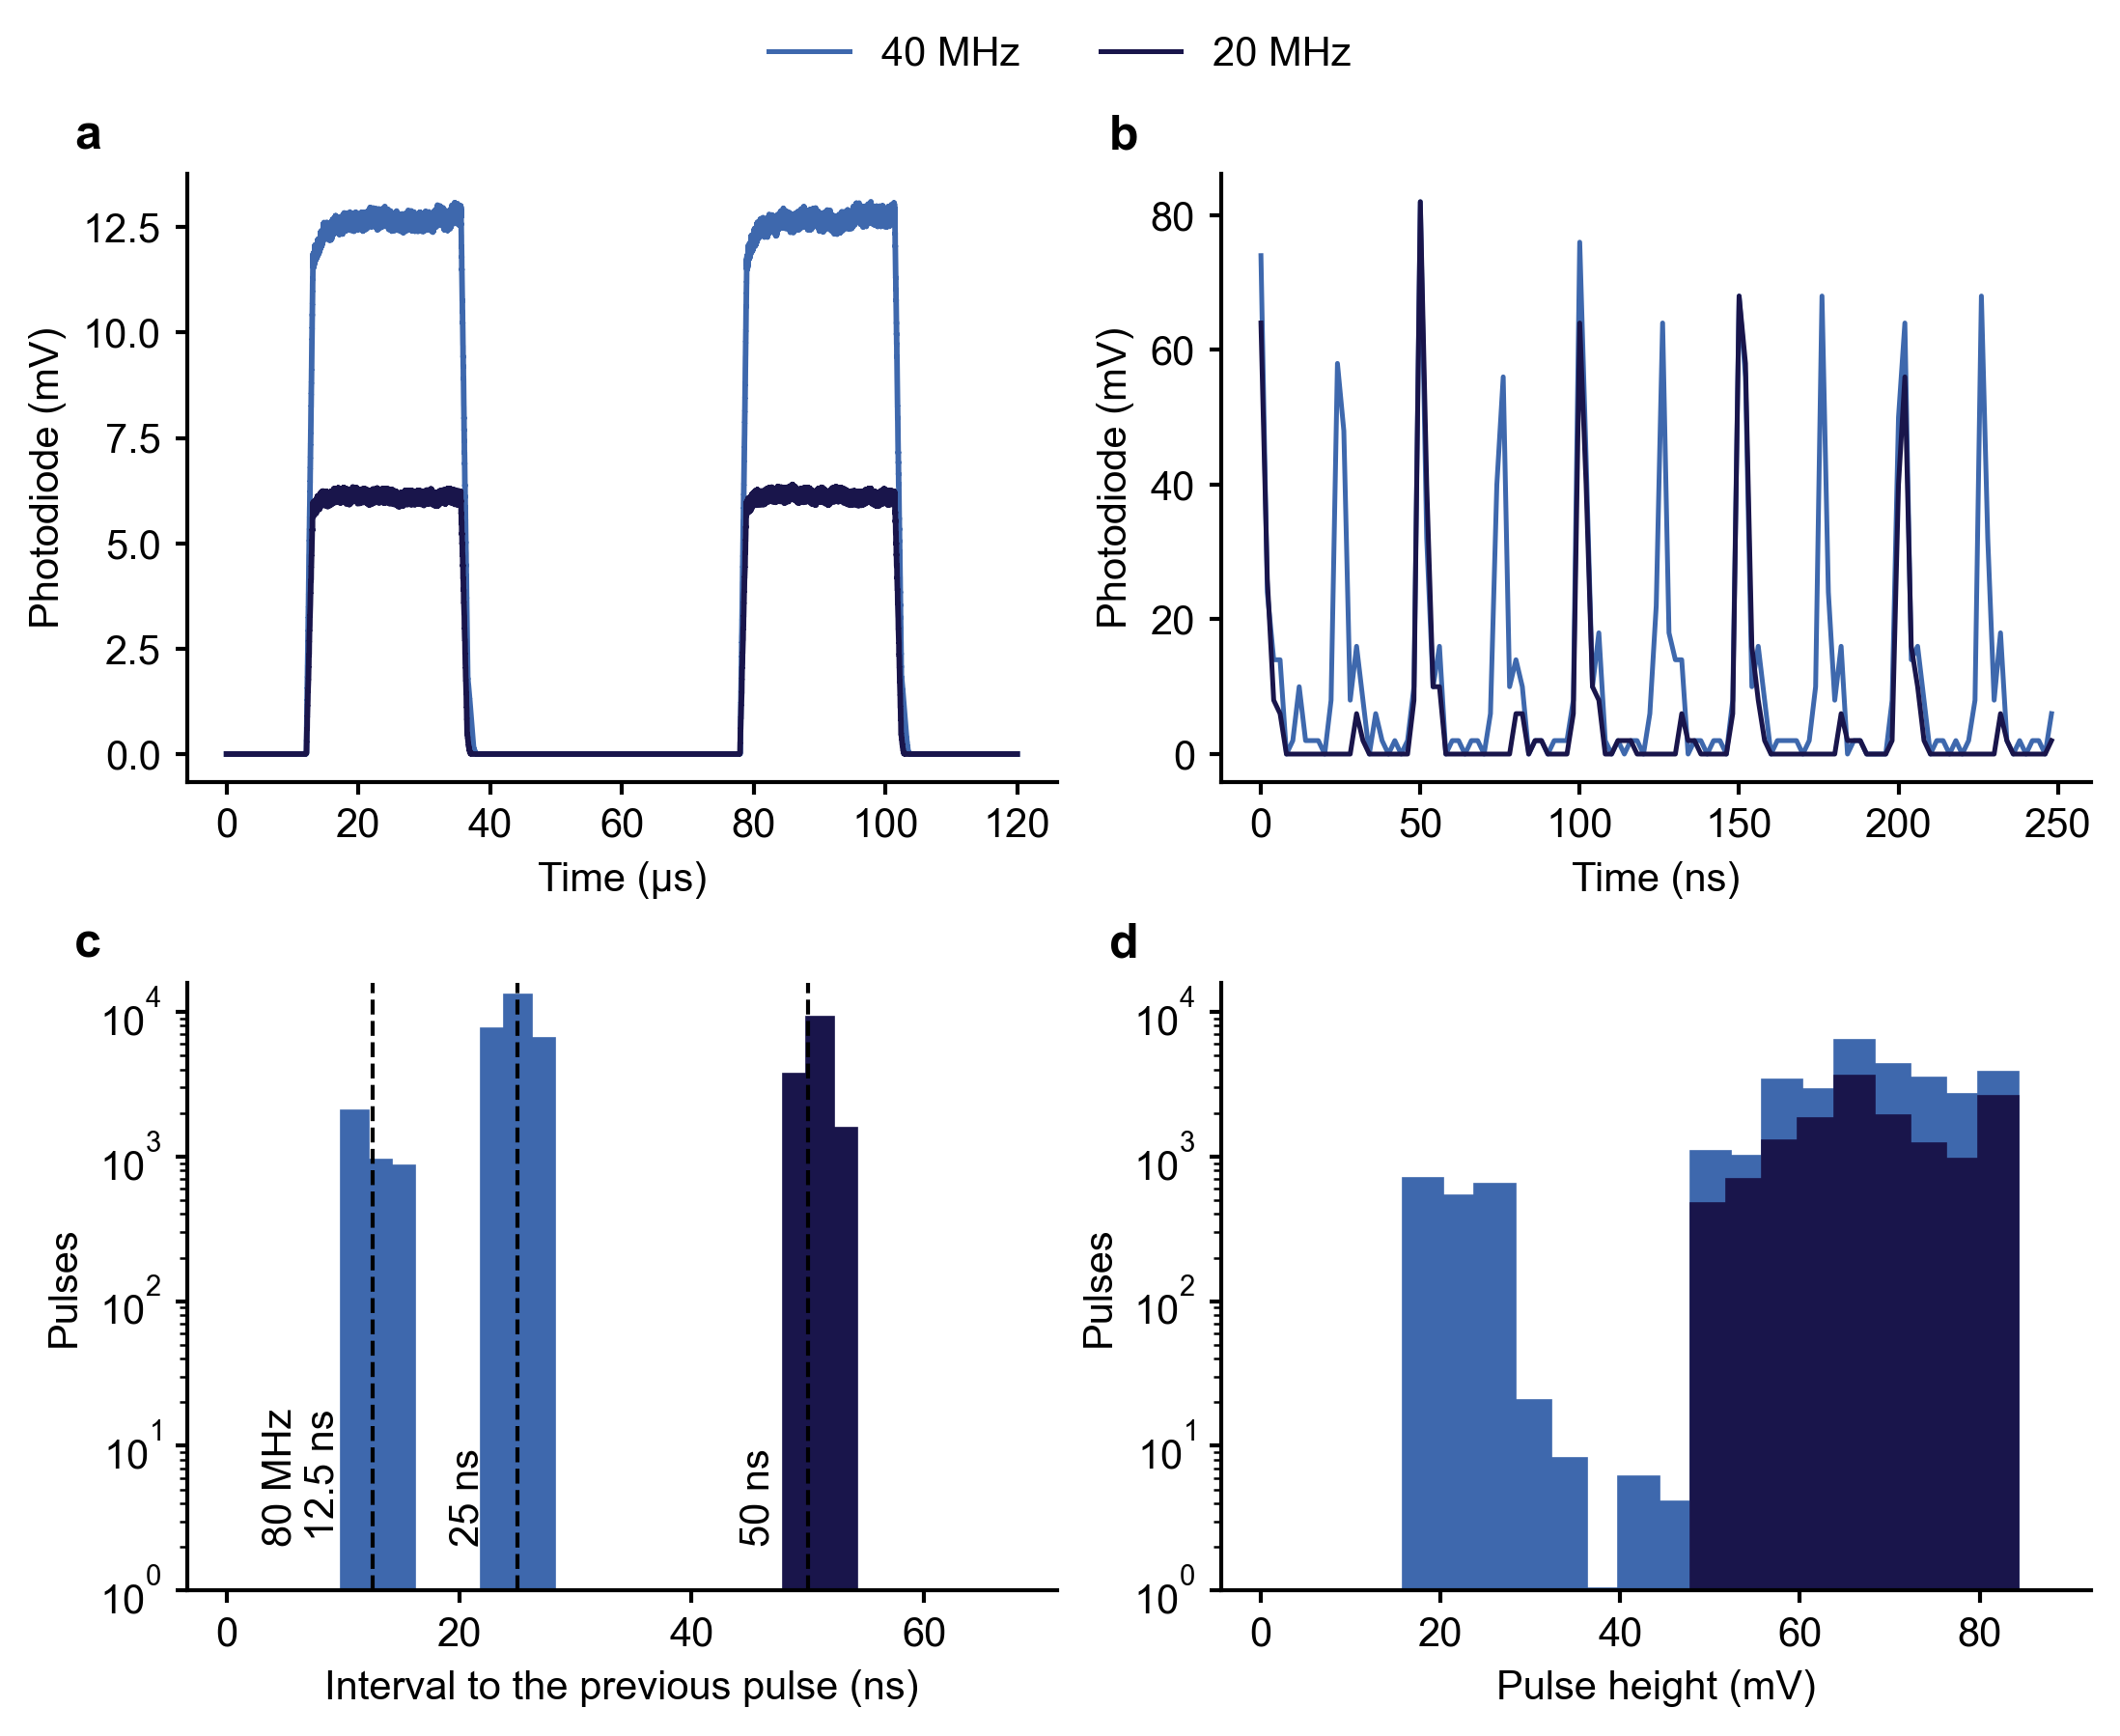

In [6]:
PEAKS, AMP = {}, {}
for name in RUNS:
    v = SIGNAL[name]
    pk, _ = find_peaks(v, height=0.2 * v.max(), distance=4)
    PEAKS[name], AMP[name] = pk, v[pk]

bins_gap = np.arange(0, 70, 2.0)    # sampling period is 2 ns
bins_amp = np.arange(0, 92, 4.0)    # vertical step is 2 mV

with paper_style():
    fig, axes = plt.subplots(2, 2, figsize=(WIDTH_2COL * MM, 150 * MM), 
                             layout="constrained", width_ratios=(1, 1))

    BOX = int(1e-6 / DT)   # 1 us, long enough to average over the pulse train

    for name, label, color in zip(RUNS, RUN_LABEL, RUN_COLORS):
        v, t = SIGNAL[name], TIME[name] * 1e6
        env = np.convolve(v, np.ones(BOX) / BOX, mode="same") * 1e3

        w = slice(0, int(120e-6 / DT))
        axes[0][0].plot(t[w] - t[w][0], env[w], lw=1.4, color=color)

        k = int(np.argmax(v[w]))
        z = slice(max(k - 25, 0), k + 100)
        axes[0][1].plot((t[z] - t[z][0]) * 1e3, v[z] * 1e3, lw=1.2, color=color, label=label)
        

        gaps = np.diff(TIME[name][PEAKS[name]]) * 1e9
        axes[1][0].hist(gaps[gaps < bins_gap[-1]], bins=bins_gap, histtype="step", lw=1.6,
                    color=color, label=label, fill=True)
        axes[1][1].hist(AMP[name] * 1e3, bins=bins_amp, histtype="step", lw=1.6,
                    color=color, label=label, fill=True)
        
    for x, txt in [(1e3 / F_LASER, "80 MHz\n12.5 ns"), (1e3 / 40, "25 ns"), (1e3 / 20, "50 ns")]:
        axes[1][0].axvline(x, color="black", ls="--", lw=1, zorder=2)
        axes[1][0].text(x - 2.7, 2, txt, fontsize=10, rotation=90,
                    ha="right", va="bottom", color="black")

    axes[1][0].set(xlabel="Interval to the previous pulse (ns)", ylabel="Pulses", yscale="log",
                ylim=(1, 10**4.2))
    #axes[0].legend(frameon=False, loc="upper right")
    axes[1][1].set(xlabel="Pulse height (mV)", ylabel="Pulses", yscale="log", ylim=(1, 10**4.2))
    #axes[1].legend(frameon=False)

    #axes[0].legend(frameon=False, loc="upper right")
    axes[0][0].set(xlabel="Time (µs)", ylabel="Photodiode (mV)")#, title="Two scanner cycles")
    axes[0][1].set(xlabel="Time (ns)", ylabel="Photodiode (mV)")#, title="Individual pulses")

    handles, labels = axes[0][1].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, loc="outside upper center", ncol=2)#, labelspacing=0.4)

    all_axes = [axes[0][0], axes[0][1], axes[1][0], axes[1][1]]
    labels = ["a", "b", "c", "d"]
    for e, ax in enumerate(all_axes):
        panel_label(ax, labels[e])

    save_paper(fig, "oscilloscope_traces")
    plt.show()

## Gating duty cycle

The duty cycle D is the mean power divided by the power while the gate is open, taken over whole
scanner periods. This is the same quantity the confocal channel in the imaging notebook measures
as the brightening from case0 to case2 (1/2.83 = 0.35).

A 1 µs boxcar turns the pulse train into an envelope. The envelope above 10 % of its maximum marks
the open gate (for the period and the leakage), and its median at least 2 µs away from the edges
is the power while the gate is open. The fraction of time above the 10 % threshold is printed for
comparison only. It counts the edges, which the boxcar widens to about 1 µs, as fully open and
comes out about 0.015 too high.

In [7]:
from scipy.ndimage import binary_erosion

BOXCAR = int(1e-6 / DT)     # 1 µs, averages over the pulse train
EDGE = int(2e-6 / DT)       # left out at both ends of each gate for the power while open
ENV, ON, DUTY = {}, {}, {}

for name in RUNS:
    v = SIGNAL[name]
    env = np.convolve(v, np.ones(BOXCAR) / BOXCAR, mode="same")
    ENV[name] = env
    ON[name] = env > 0.1 * env.max()
    edges = np.flatnonzero(np.diff(ON[name].astype(int)) != 0)
    period = np.median(np.diff(edges[::2])) * DT if len(edges) > 4 else np.nan
    on_power = v[ON[name]].mean()
    off_power = v[~ON[name]].mean()

    # D = mean power over whole scanner periods / power while the gate is open
    rises = np.flatnonzero(np.diff(ON[name].astype(int)) == 1)
    core = binary_erosion(ON[name], structure=np.ones(2 * EDGE + 1, bool))
    DUTY[name] = v[rises[0]:rises[-1]].mean() / np.median(env[core])

    print(f"{name}:  duty {DUTY[name]:.3f}  (time above 10 %: {ON[name].mean():.3f})   "
          f"gating period {period*1e6:.1f} µs ({1e-3/period:.2f} kHz)   off/on power {off_power/on_power:.2e}")

2026-10-12_40mhz:  duty 0.358  (time above 10 %: 0.376)   gating period 65.8 µs (15.19 kHz)   off/on power 7.41e-04


2026-10-12_20mhz:  duty 0.355  (time above 10 %: 0.371)   gating period 65.8 µs (15.19 kHz)   off/on power 8.72e-05


In [8]:
# split into picked pulses and whatever leaked through
for name, label in zip(RUNS, RUN_LABEL):
    amp = AMP[name]
    full = np.median(amp[amp > 0.5 * amp.max()])
    small = amp < 0.5 * full
    rate = (~small).sum() / (len(SIGNAL[name]) * DT * DUTY[name]) / 1e6   # picked pulses only
    print(f"{label}:")
    print(f"   {len(amp)} pulses, {small.sum()} of them below half height")
    print(f"   picked pulses per open time: {rate:.1f} MHz   (set to {F_PICK[RUNS.index(name)]:.0f})")
    print(f"   median height {np.median(amp[~small])*1e3:.1f} mV, "
          f"leaked pulses carry {100*amp[small].sum()/amp.sum():.1f} % of the total amplitude")

40 MHz:
   30339 pulses, 1859 of them below half height
   picked pulses per open time: 39.8 MHz   (set to 40)
   median height 66.0 mV, leaked pulses carry 2.0 % of the total amplitude
20 MHz:
   14210 pulses, 0 of them below half height
   picked pulses per open time: 20.0 MHz   (set to 20)
   median height 66.0 mV, leaked pulses carry 0.0 % of the total amplitude


## 2P prediction

Fluorescence goes with the square of the instantaneous intensity, so for a train of identical
pulses the 2p signal is proportional to the sum of the squared pulse energies, while the power
meter sees the plain sum. Because every pulse has the same shape at the photodiode, integrating
the trace gives both directly:

    average power   ∝ ∫v dt
    2p signal       ∝ ∫v² dt
    at equal power  →  FOM = T · ∫v² dt / (∫v dt)²

The ratio of FOM between the two traces is what the pulse train alone predicts for the 2p gain at
the 2 mW the images were taken at. Ideal picking from 40 to 20 MHz would give exactly 2.

In [9]:
S1 = np.array([SIGNAL[n].sum() * DT for n in RUNS])          # ∫v dt
S2 = np.array([(SIGNAL[n] ** 2).sum() * DT for n in RUNS])   # ∫v² dt
T = np.array([len(SIGNAL[n]) * DT for n in RUNS])
FOM = T * S2 / S1 ** 2

print(f"{'':16}{'∫v dt (µV s)':>15}{'∫v² dt':>12}{'FOM':>10}")
for k, label in enumerate(RUN_LABEL):
    print(f"{label:16}{S1[k]*1e6:15.3f}{S2[k]*1e9:12.3f}{FOM[k]:10.2f}")

ratio = FOM[1] / FOM[0]
print(f"\naverage power 20/40 MHz           {S1[1]/S1[0]:>8.3f}")
print(f"predicted 2p gain 20/40 MHz      {ratio:>8.2f}")
print(f"ideal                                2.00")

                   ∫v dt (µV s)      ∫v² dt       FOM
40 MHz                    9.201     382.098      9.03
20 MHz                    4.434     191.415     19.47

average power 20/40 MHz              0.482
predicted 2p gain 20/40 MHz          2.16
ideal                                2.00
